In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as cm
import glob
from matplotlib.colors import ListedColormap
from scipy.spatial import cKDTree
from emagpy import Problem
import numpy as np
from math import floor, ceil
from scipy.stats import gmean
from math import sqrt, pi
import matplotlib
from pathlib import Path
from matplotlib import colors
from numpy.polynomial import Polynomial as P
from scipy.interpolate import griddata
from pathlib import Path
import econflux as ec

### Define font properties

titleFontKws = {
    'fontsize': 16,
    'fontweight': 'bold',
    }

subtitleFontKws = {
    'fontsize': 12,
    'fontweight': 'bold',
    }

labelFontKws = {
    'fontsize': 14,
    'fontweight': 'bold',
    }

tickLabelFontKws = {
    'labelsize': 10,
    }

cbarTitleKws = {
    'fontsize': 14,
    'fontweight': 'bold'}

cbarTickKws = {
    'fontsize': 12,
    }

# Define font parameters
plt.rcParams['font.family'] = 'Cambria'
plt.rcParams['font.weight'] = 'bold'

fontkwDict = {'fontfamily': 'Cambria',
              'fontweight': 'bold',
              'titlefontsize': titleFontKws['fontsize'],
              'titlefontweight': titleFontKws['fontweight'],
              'axislabelsize': labelFontKws['fontsize'],
              'axislabelweight': labelFontKws['fontweight'],
              'axisticksize': tickLabelFontKws['labelsize'],
              'cbartitlesize': cbarTitleKws['fontsize'],
              'cbartitleweight': cbarTitleKws['fontweight'],
              'cbarticklabelsize': cbarTickKws['fontsize']}

In [2]:
# Paths to images and other files
datDir = r'C:\Users\Chris\Documents\GitHub\EConflux\examples\dl_resistive_ag_er2em\\'
emifile_path = datDir + "UDel_UTM_ECa.csv" # EMI ECa to be informed from test site linear regression model parameters

# Calibration files (ERT-derived EC and raw/ECa calibration table)
ECa = datDir + "df_eca.csv" # EMI ECa from a test site in Princess Anne, Maryland
EC  = datDir + "df_ec.csv" # Inverted ERI from a test site in Princess Anne, MAryland
ERTval = pd.read_csv(datDir + "Del_ResAG_Conductivity_Models.csv") # Two 3D ERI inversion results combined for validation

# er2em at Delaware Agricultural Site
---
The linear regression parameters used to inform the EMI for this example were developed with a 2D Electrical Resistivity Imaging (ERI) profile and an EMI survey conducted at a test site in Maryland (Thompson et al 2026; in review). The ERI data used for validation came from two 3D ERI surveys at two different locations within the Delaware field. The first location had mostly sandy soils and the other plot contained more fine-textured soils. Therefore, the comparison with the ERI is a combined inverted ERI results comparison with the informed EMI inversion results. Both ERI survey consisted of 48 electrodes in a 3D grid.


<img src="Survey_Layout.png" width="400">

# Inverting the informed and the raw EMI measurements

Removing 1 NaN from survey
1182/7556 data removed (filterRange).
130/6374 data removed (fitlerPercentile).
183/6244 data removed (fitlerPercentile).
127/6061 data removed (fitlerPercentile).
124/5934 data removed (fitlerPercentile).
147/5810 data removed (fitlerPercentile).
121/5663 data removed (fitlerPercentile).
dataset shrunk of 9 measurements
Removing 1 NaN from survey


C:\Users\Chris\miniconda3\envs\geophysics\Lib\site-packages\emagpy\invertHelper.py:296: RuntimeWarning: invalid value encountered in divide
  R[i,:] = (gamma[i,:]-gamma[i+1,:])/(gamma[i,:]+gamma[i+1,:]) \
C:\Users\Chris\miniconda3\envs\geophysics\Lib\site-packages\emagpy\invertHelper.py:298: RuntimeWarning: invalid value encountered in divide
  R[i,:] /= 1+(gamma[i,:]-gamma[i+1,:])/(gamma[i,:]+gamma[i+1,:]) \


HCP1.0: ECa (ERT) = 0.83 * ECa (EMI) -3.67 (R^2=0.66)
PRP1.1: ECa (ERT) = 2.13 * ECa (EMI) -0.59 (R^2=0.58)
HCP2.0: ECa (ERT) = 0.94 * ECa (EMI) -2.50 (R^2=0.74)
PRP2.1: ECa (ERT) = 1.37 * ECa (EMI) -1.23 (R^2=0.78)
HCP4.0: ECa (ERT) = 0.68 * ECa (EMI) -1.00 (R^2=0.68)
PRP4.1: ECa (ERT) = 0.98 * ECa (EMI) -1.43 (R^2=0.71)
Correction is applied.
1395/7556 data removed (filterRange).
128/6161 data removed (fitlerPercentile).
184/6033 data removed (fitlerPercentile).
124/5849 data removed (fitlerPercentile).
122/5725 data removed (fitlerPercentile).
138/5603 data removed (fitlerPercentile).
111/5465 data removed (fitlerPercentile).
dataset shrunk of 9 measurements


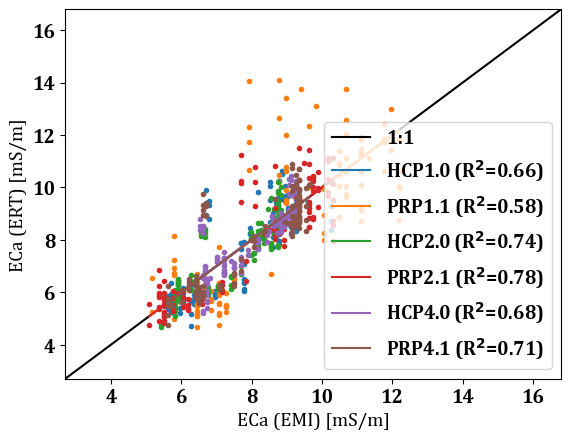

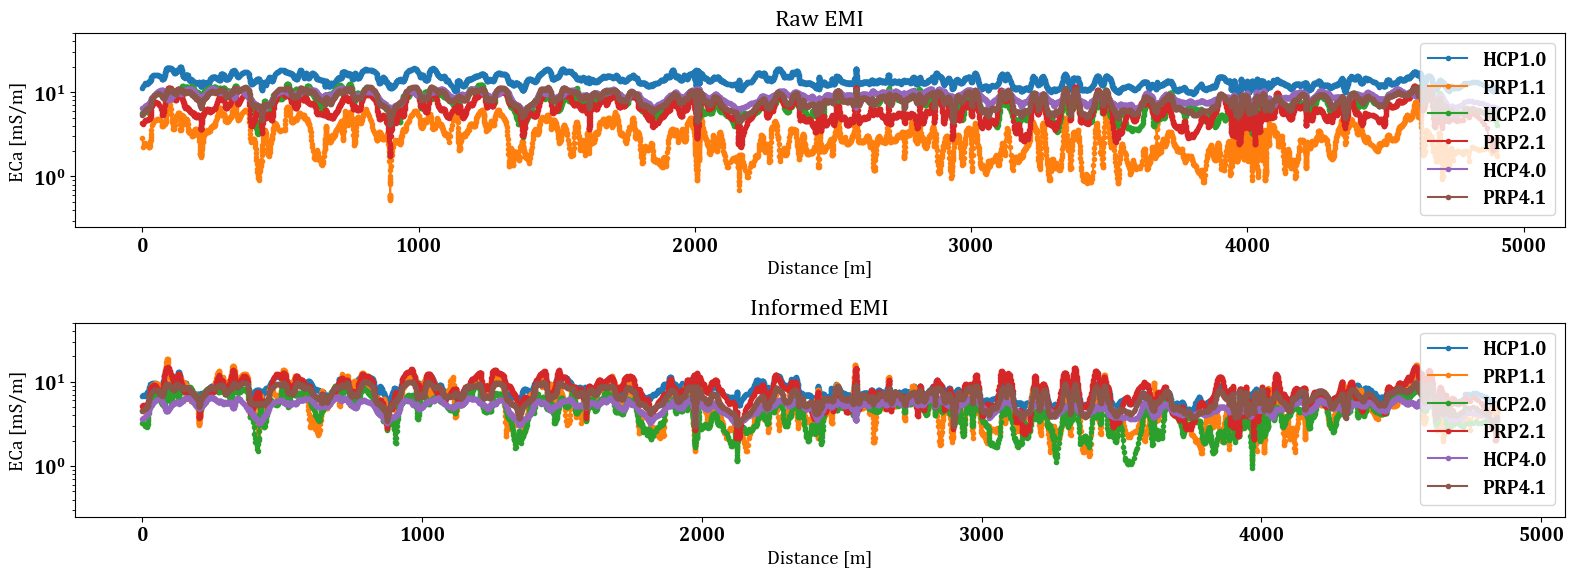


--- Running branch: Raw ---
Removing 1 NaN from survey
1182/7556 data removed (filterRange).
130/6374 data removed (fitlerPercentile).
183/6244 data removed (fitlerPercentile).
127/6061 data removed (fitlerPercentile).
124/5934 data removed (fitlerPercentile).
147/5810 data removed (fitlerPercentile).
121/5663 data removed (fitlerPercentile).
dataset shrunk of 9 measurements
5533/5533 inverted

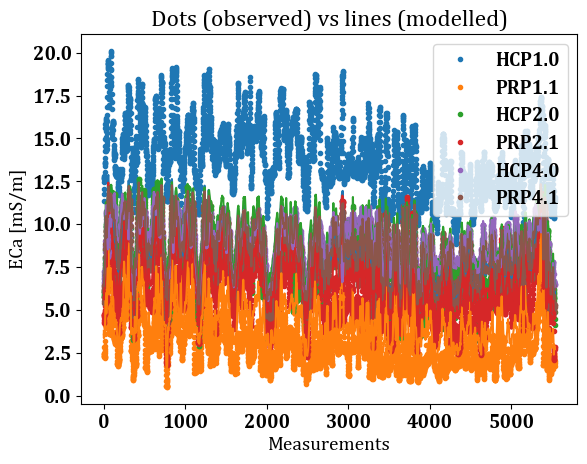

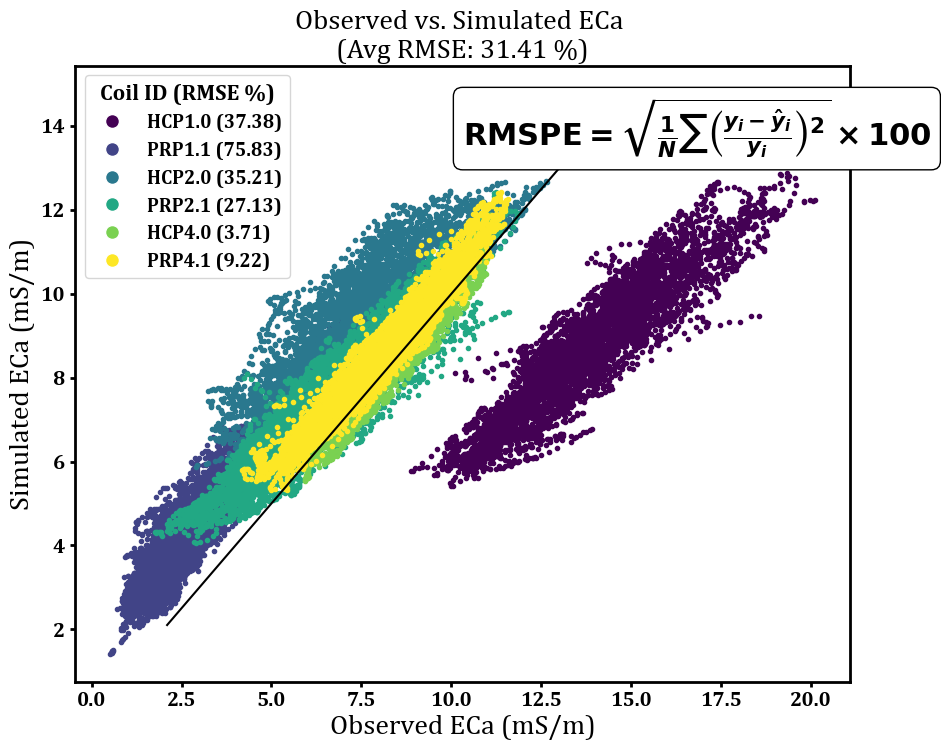

C:\Users\Chris\miniconda3\envs\geophysics\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\Chris\miniconda3\envs\geophysics\Lib\site-packages\emagpy\invertHelper.py:296: RuntimeWarning: invalid value encountered in divide
  R[i,:] = (gamma[i,:]-gamma[i+1,:])/(gamma[i,:]+gamma[i+1,:]) \
C:\Users\Chris\miniconda3\envs\geophysics\Lib\site-packages\emagpy\invertHelper.py:298: RuntimeWarning: invalid value encountered in divide
  R[i,:] /= 1+(gamma[i,:]-gamma[i+1,:])/(gamma[i,:]+gamma[i+1,:]) \


Saved long: C:\Users\Chris\Documents\GitHub\EConflux\examples\dl_resistive_ag_er2em\\d1_calF2_inv_Raw.csv   (rows=33,277)
Saved wide: C:\Users\Chris\Documents\GitHub\EConflux\examples\dl_resistive_ag_er2em\\d1_calF2_inv_Raw_WIDE.csv   (shape=(5533, 17))

--- Running branch: Informed ---
Removing 1 NaN from survey
HCP1.0: ECa (ERT) = 0.83 * ECa (EMI) -3.67 (R^2=0.66)
PRP1.1: ECa (ERT) = 2.13 * ECa (EMI) -0.59 (R^2=0.58)
HCP2.0: ECa (ERT) = 0.94 * ECa (EMI) -2.50 (R^2=0.74)
PRP2.1: ECa (ERT) = 1.37 * ECa (EMI) -1.23 (R^2=0.78)
HCP4.0: ECa (ERT) = 0.68 * ECa (EMI) -1.00 (R^2=0.68)
PRP4.1: ECa (ERT) = 0.98 * ECa (EMI) -1.43 (R^2=0.71)
Correction is applied.
1395/7556 data removed (filterRange).
128/6161 data removed (fitlerPercentile).
184/6033 data removed (fitlerPercentile).
124/5849 data removed (fitlerPercentile).
122/5725 data removed (fitlerPercentile).
138/5603 data removed (fitlerPercentile).
111/5465 data removed (fitlerPercentile).
dataset shrunk of 9 measurements
5345/5345 inver

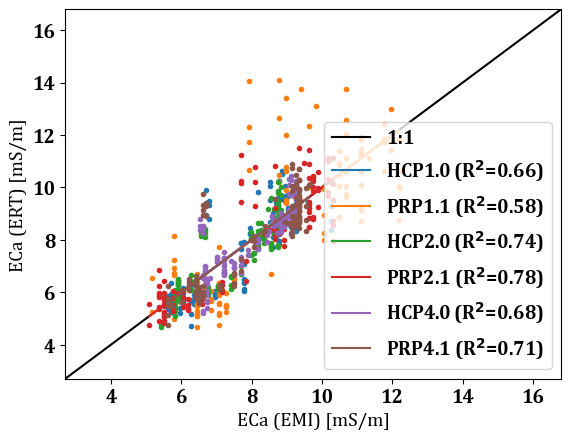

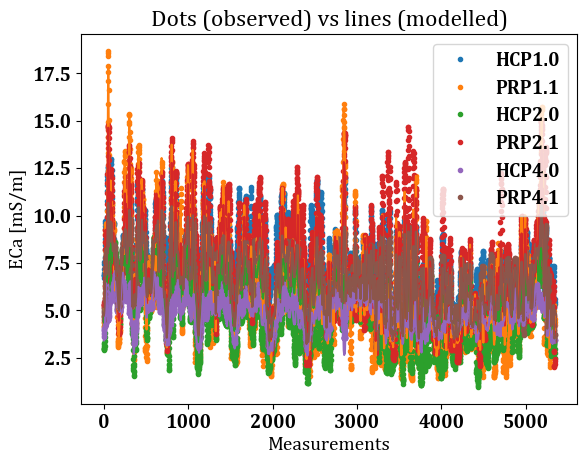

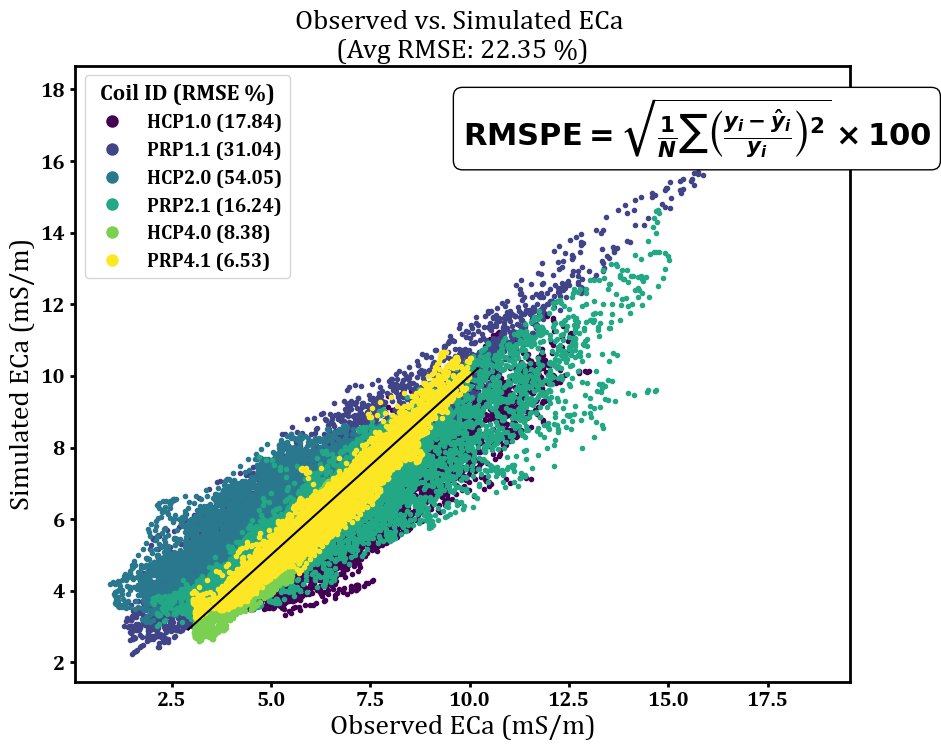

Saved long: C:\Users\Chris\Documents\GitHub\EConflux\examples\dl_resistive_ag_er2em\\d1_calF2_inv_Informed.csv   (rows=37,159)
Saved wide: C:\Users\Chris\Documents\GitHub\EConflux\examples\dl_resistive_ag_er2em\\d1_calF2_inv_Informed_WIDE.csv   (shape=(5345, 17))


C:\Users\Chris\miniconda3\envs\geophysics\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [3]:
# --- Inputs needed to (re)build the Problem in each loop ---
freq = 9000
coilHgt = 0.0 # Instrument was pulled on the ground

# Calibration settings
cal_forwardModel = "FSlin" # Highly resistive soils. Mostly sandy to silt loams
cal_meshType = "tri" # From your ERI mesh

# Inversion parameters (your provided settings)
num_layers = 7
start_dpth = 0.3
inv_forwardModel = "FSlin"
inv_method = "Gauss-Newton"
inv_alpha = 0.03
inv_regularization = "l2"

# Filtering settings (matching your earlier workflow)
filtRange = [0.25, 50]
filtPct = True
rollWindow = 10

# Plot settings (matching your earlier workflow)
calLog = False
plot_figsize = (16, 6)

# =============================================================================
# HELPERS
# =============================================================================
def apply_filtering(k):
    """
    Applies the same filtering sequence you use elsewhere:
      1) filterRange
      2) filterPercentile (per coil)
      3) rollingMean
    """
    k.filterRange(filtRange[0], filtRange[1])

    if filtPct:
        for i in range(len(k.coils)):
            k.filterPercentile(coil=k.coils[i], qmin=1, qmax=99)

    k.rollingMean(window=rollWindow)
    return k

# The functions below loop through the EMI data and will invert the informed and raw EMI ECa independently.
def export_inversion_to_long_csv(k, out_csv_path):
    """
    Your export logic (with a small fix to the DataFrame columns definition).
    Writes a long-format CSV: x, y, Z, Log(Conductivity mS/m), conductivity
    Requires k.models[0] and k.depths[0] (produced by k.invert).
    """

    if not hasattr(k, "surveys") or len(k.surveys) == 0:
        raise ValueError("k has no surveys. Did you call k.createSurvey(...) ?")

    if not hasattr(k, "models") or len(k.models) == 0 or k.models[0] is None:
        raise ValueError("k.models[0] is missing. Run k.invert(...) before exporting.")

    if not hasattr(k, "depths") or len(k.depths) == 0 or k.depths[0] is None:
        raise ValueError("k.depths[0] is missing. Run k.invert(...) before exporting.")

    if not set(["x", "y"]).issubset(set(k.surveys[0].df.columns)):
        raise ValueError("k.surveys[0].df must contain 'x' and 'y' columns for this export.")

    lay = int(k.models[0].shape[1])

    lcol = ['layer{:d}'.format(a + 1) for a in range(k.models[0].shape[1])]
    dcol = ['depth{:d}'.format(a + 1) for a in range(k.depths[0].shape[1])]

    data = np.c_[k.surveys[0].df[['x', 'y']].values, k.models[0], k.depths[0]]

    # FIX: columns must be a flat list
    df = pd.DataFrame(data, columns=(['x', 'y'] + lcol + dcol))

    col = lay + 2
    locations = df.iloc[:, :2]
    layers = df.iloc[:, 2:col]
    depth = df.iloc[:, col:] * -1

    layers_melt = pd.melt(layers).iloc[:, 1]
    depth_melt = pd.melt(depth).iloc[:, 1]

    conduct = pd.DataFrame({'conductivity': layers_melt, 'Z': depth_melt})

    logcon = np.log10(conduct['conductivity'])
    conduct['Log(Conductivity mS/m)'] = logcon

    conduct = conduct[['Z', 'Log(Conductivity mS/m)', 'conductivity']]

    x = pd.concat([locations.iloc[:, 0]] * lay, ignore_index=True)
    y = pd.concat([locations.iloc[:, 1]] * lay, ignore_index=True)

    xy = pd.DataFrame({'x': x, 'y': y})
    conduct.insert(0, 'y', xy.iloc[:, 1])
    conduct.insert(0, 'x', xy.iloc[:, 0])

    conduct = conduct.dropna()
    conduct.to_csv(out_csv_path, index=False)

    return conduct

def format_axis_like_your_script(ax):
    """
    Matches your earlier axis formatting block.
    """
    ax.set_ylim(filtRange[0], filtRange[1])

    if not calLog:
        # ax.set_yscale('log')
        ax.yaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())
        ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%d'))
        ax.yaxis.set_major_formatter(
            matplotlib.ticker.FuncFormatter(lambda x, pos: str(int(round(x))))
        )


def inverted_model_to_wide_df(k):
    """
    Store the inverted model (k.models[0]) + depths (k.depths[0]) as a WIDE DataFrame
    with columns:
      x, y, layer1..layerN, depth1..depthN
    (This mirrors the intermediate wide table you build inside export_inversion_to_long_csv.)
    """
    if not hasattr(k, "models") or len(k.models) == 0 or k.models[0] is None:
        raise ValueError("k.models[0] is missing. Run k.invert(...) first.")
    if not hasattr(k, "depths") or len(k.depths) == 0 or k.depths[0] is None:
        raise ValueError("k.depths[0] is missing. Run k.invert(...) first.")
    if not set(["x", "y"]).issubset(set(k.surveys[0].df.columns)):
        raise ValueError("k.surveys[0].df must contain 'x' and 'y' columns.")

    lcol = ['layer{:d}'.format(a + 1) for a in range(k.models[0].shape[1])]
    dcol = ['depth{:d}'.format(a + 1) for a in range(k.depths[0].shape[1])]

    data = np.c_[k.surveys[0].df[['x', 'y']].values, k.models[0], k.depths[0]]
    df_wide = pd.DataFrame(data, columns=(['x', 'y'] + lcol + dcol))
    return df_wide

# BUILD ONE k, PLOT ONCE, THEN RUN TWO BRANCHES FOR OUTPUTS
# ---- Build a single uncalibrated k for plotting left panel ----
k_plot_uncal = Problem()
k_plot_uncal.createSurvey(str(emifile_path), freq=freq, hx=coilHgt)
k_plot_uncal = apply_filtering(k_plot_uncal)

# ---- Build a separate calibrated copy for plotting right panel ----
k_plot_cal = Problem()
k_plot_cal.createSurvey(str(emifile_path), freq=freq, hx=coilHgt)
k_plot_cal.calibrate(
    fnameECa=str(ECa),
    fnameEC=str(EC),
    forwardModel=cal_forwardModel,
    meshType=cal_meshType,
    apply=True
)
k_plot_cal = apply_filtering(k_plot_cal)

# ---- PLOT ONCE: uncalibrated (axs[0]) and calibrated (axs[1]) ----
fig, axs = plt.subplots(2, figsize=plot_figsize)

format_axis_like_your_script(axs[0])
k_plot_uncal.show(coil='all', ax=axs[0])
axs[0].set_title('Raw EMI')
axs[0].set_yscale('log')

format_axis_like_your_script(axs[1])
k_plot_cal.show(coil='all', ax=axs[1])
axs[1].set_title('Informed EMI')
axs[1].set_yscale('log')

plt.tight_layout()
plt.show()

# NOW RUN BOTH BRANCHES (uncalibrated + calibrated) WITHOUT ANY MORE PLOTS
# AND STORE INVERTED MODELS AS DATAFRAMES
df_uncal_long = None
df_cal_long = None
df_uncal_wide = None
df_cal_wide = None

for do_calibrate, tag in [(False, "Raw"), (True, "Informed")]:

    print(f"\n--- Running branch: {tag} ---")

    # 1) Create k fresh each branch
    k = Problem()
    k.createSurvey(str(emifile_path), freq=freq, hx=coilHgt)

    # 2) Optional calibration
    if do_calibrate:
        k.calibrate(
            fnameECa=ECa,
            fnameEC=EC,
            forwardModel=cal_forwardModel,
            meshType=cal_meshType,
            apply=True
        )

    # 3) Filtering BEFORE inversion (matches your workflow)
    k = apply_filtering(k)

    # 4) Construct forward model
    depths = np.linspace(start_dpth, 6.3, 7)
    eca_cols = [col for col in k.surveys[0].df.iloc[:, 2:-1] if '_inph' not in col]
    ecaAvg = np.mean(gmean(k.surveys[0].df[eca_cols]))
    conds = np.ones(len(depths)+1)*ecaAvg
    k.setInit(depths0=depths,
              fixedDepths=np.ones(len(depths), dtype='bool'),
              conds0=conds,
              fixedConds=np.zeros(len(conds), dtype='bool'))

    # 4) Invert with your exact parameters
    k.invert(
        forwardModel=inv_forwardModel,
        method=inv_method,
        alpha=inv_alpha,
        regularization=inv_regularization
    )

    # 5) Store the inverted model as a WIDE DataFrame (in memory + optional CSV)
    df_wide = inverted_model_to_wide_df(k)
    wide_csv = os.path.join(datDir, f"d1_calF2_inv_{tag}_WIDE.csv")
    df_wide.to_csv(wide_csv, index=False)

    k.showMisfit()
    k.showOne2one(index=0)
    
    # 6) Export long-format inversion output (in memory + CSV)
    out_csv = os.path.join(datDir, f"d1_calF2_inv_{tag}.csv")
    df_long = export_inversion_to_long_csv(k, out_csv)

    # 7) Save DataFrames into named variables
    if tag == "Raw":
        df_uncal_wide = df_wide
        df_uncal = df_long
    else:
        df_cal_wide = df_wide
        df_cal = df_long

    print(f"Saved long: {out_csv}   (rows={len(df_long):,})")
    print(f"Saved wide: {wide_csv}   (shape={df_wide.shape})")

In [4]:
EMIc = df_cal
EMInc = df_uncal
dflist = [EMIc, EMInc]
dfnames = ['cal', 'nc']
mapper = ec.er2em.DataMapper(num_neighbors=1, max_distance_xy=5, max_distance_z = 0.5)  # Adjust parameters as needed
inverted_conductivity_models, distances_xy = mapper.mapXYZ(ERTval, dflist, dfnames, topo_correct=False)

# Visual Assessment of the two 3D ERI plots and the informed and raw EMI inversion results.
---
<img src= "3D_Visualv4.png" width="800">

# Statistical comparison between the informed and raw EMI inversion results and the combined 3D ERI inversion results
---
Note - the ERI inversion results used below were not applied in the informed er2em workflow. This combined 3D ERI inversion results are used just for validation.

In [5]:
inverted_conductivity_models.to_csv('invConductivity.csv', index = None)

             Informed (EMI vs ERI)  Raw (EMI vs ERI)
KGE_np                        0.40              0.19
KGE_alpha                     0.87              0.96
KGE_beta                      0.84              1.27
KGE_r                         0.43              0.24
KGE_2009                     -0.26             -0.01
KGE_2012                     -0.65             -0.06
NSE                          -2.74             -1.69
R²                            0.32              0.01
Pearson r                     0.57              0.08
Spearman r                    0.43              0.24
ME                           -0.13              0.21
MAE                           0.24              0.22
RMSE                          0.36              0.30
NRMSE_range                   0.15              0.13


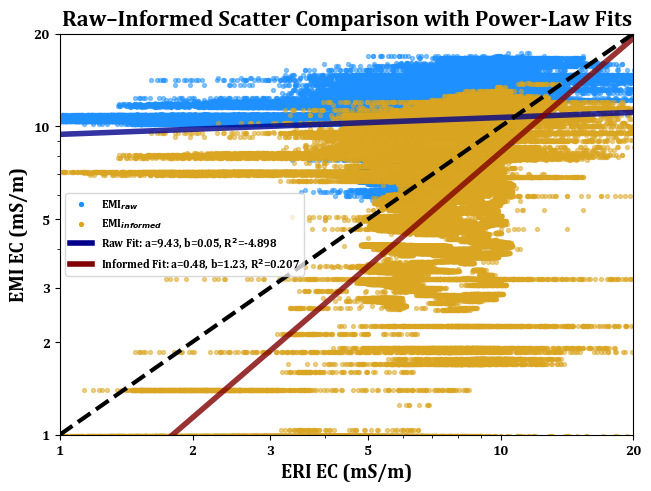

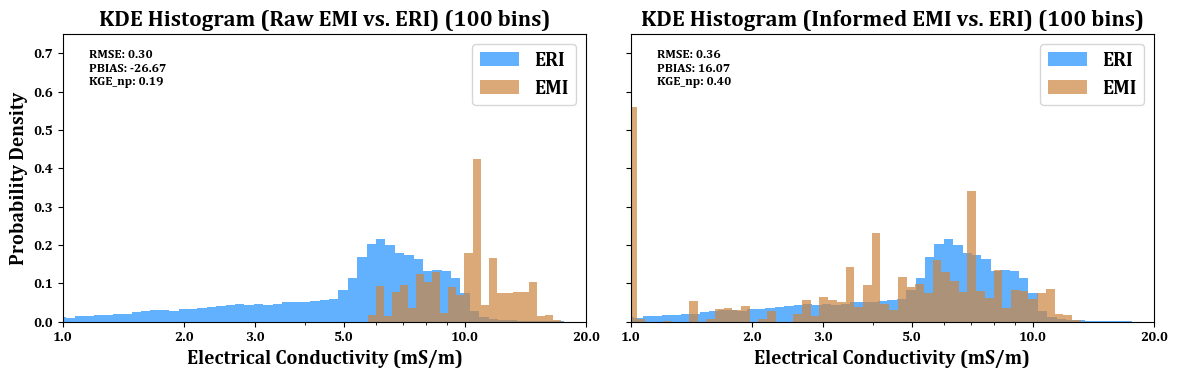

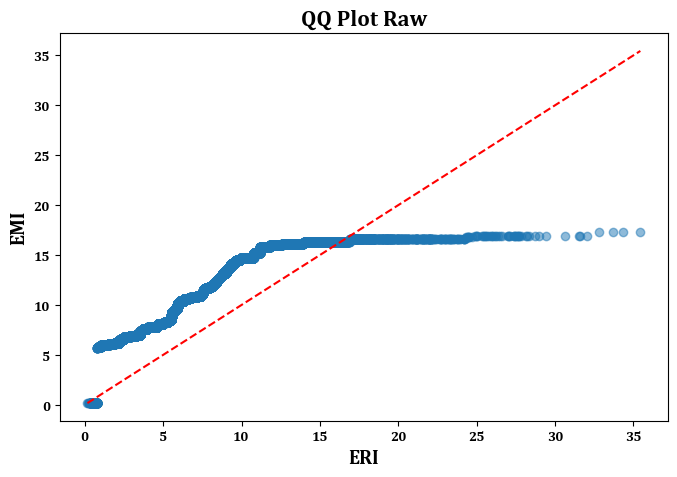

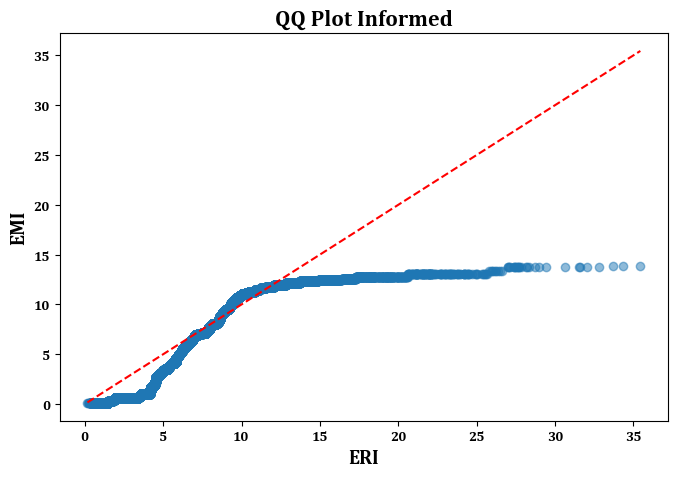


Median Difference: 3.614 mS/m
Upper Limit of Agreement: 9.131 mS/m
Lower Limit of Agreement: -0.544 mS/m

Median Difference: -1.105 mS/m
Upper Limit of Agreement: 4.937 mS/m
Lower Limit of Agreement: -5.885 mS/m


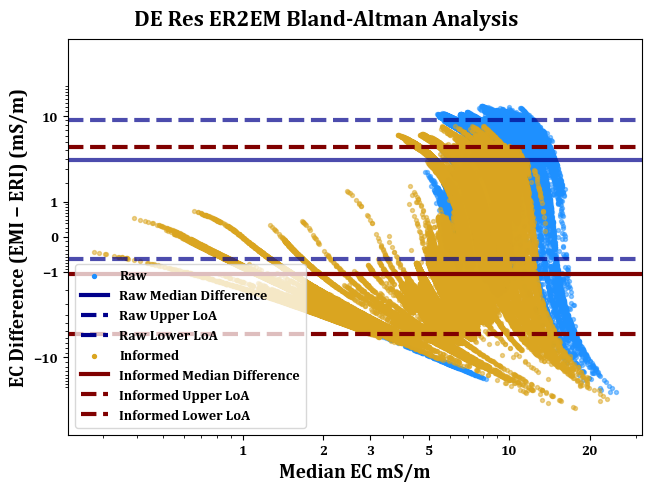

In [6]:
nonparam = True
site = 'de_res_ag_er2em'
figdir = datDir + 'figures\\'

ticks = [1, 2, 3, 5, 10, 20]

logList = [1, 1]   # List dictating whether to use log (1) or linear (0) scales for the Bland-Altman plots

j = ec.vse.EConfluxStats('invConductivity.csv', 'Conductivity(mS/m)', 'nc_conductivity', 'cal_conductivity', 
                  drop_flag_col=None, informingMethod='ERI', informedMethod='EMI', ticks=ticks, **fontkwDict)

# Get metrics table
print(j.metrics(logOrlin='log', decompKGE=True))

# Make plots

dbounds = [0, 0.5, 1.0, 1.6, 2.0, 3.2, 5.2]
cmap = 'viridis'

j.scatter_plots(log=True, grayscale=False, figname=figdir + site + '_scatter.png')

j.kde_histograms(figname=figdir + site + '_kde.png', nbins=100, ylims=[0, 0.75])

j.qq_plot(j.X, j.y, xlabel="ER", ylabel="Raw EM", title="QQ Plot Raw", figname=figdir + site + '_rawQQ.png')

j.qq_plot(j.X, j.Y, xlabel="ER", ylabel="Informed EM", title="QQ Plot Informed", figname=figdir + site + '_infQQ.png')

### Bland-Altman Plots ###
fig, ax = plt.subplots(layout='constrained')

rawKws = {'label': 'Raw', 'color': 'dodgerblue', 'alpha': 0.5}
rawLineKws = {'color': 'darkblue', 'alpha': 0.7, 'linestyle': ['-', '--'], 'linewidth': 3, 'label': ['Raw Median Difference', 'Raw Upper LoA', 'Raw Lower LoA']}
infKws = {'label': 'Informed', 'color': 'goldenrod', 'alpha': 0.5}
infLineKws = {'color': 'maroon', 'alpha': 1, 'linestyle': ['-', '--'], 'linewidth': 3, 'label': ['Informed Median Difference', 'Informed Upper LoA', 'Informed Lower LoA']}

# Bland-Altman for raw EM vs ER
j.bland_altman(j.y, j.X, ax=ax, ymin=-50, ymax=50, marker='o', markersize=8, xmin=None, xmax=None, savefig=False, figname=None,
               xticks=ticks, logList=logList, nonparam=nonparam, legendParams={'plot': True, 'loc': 'lower left'}, linekwargs=rawLineKws, **rawKws)

# Bland-Altman for informed EM vs ER
j.bland_altman(j.Y, j.X, ax=ax, ymin=-50, ymax=50, marker='o', markersize=8, xmin=None, xmax=None, savefig=False, figname=None, 
               xticks=ticks, logList=logList, nonparam=nonparam, legendParams={'plot': True, 'loc': 'lower left'}, linekwargs=infLineKws, **infKws)

# Plot Detailing
if dbounds is not None:
    if plt.get_cmap(cmap).N == 256:
        dcmap = plt.get_cmap(cmap, len(dbounds))
    norm = colors.BoundaryNorm(dbounds, ncolors=len(dbounds))
else:
    norm = colors.Normalize(vmin=0, vmax=abs(j.data['Z'].min()))
            
cmmapable = cm.ScalarMappable(norm, dcmap)

fig.suptitle('DE Res ER2EM Bland-Altman Analysis', **titleFontKws)
ax.set_ylabel("EC Difference " + f"({j.informedMethod} − {j.informingMethod}) ({j.units})", **labelFontKws)
if nonparam:
    ax.set_xlabel("Median EC " + (f"{j.units}"), **labelFontKws)
else:
    ax.set_xlabel("Mean EC " + (f"{j.units}"), **labelFontKws)

plt.savefig(figdir + site + '_bland_altman.png', dpi=300)